# Predicció 2026: el millor model per cada sèrie (backtest 2025)

Per generar la predicció anual del 2026 fem servir el **model guanyador del backtest 2025** per a cada sèrie. El backtest 2025 és l'experiment més directament anàleg a aquesta previsió: ambdós casos són una predicció a 12 mesos vista a partir d'un horitzó de train recent (108 mesos vs 96), una sola realització del problema. El WFV (mitjana sobre 13 folds) és útil per estimar el rendiment operatiu mig a llarg termini, però aquí l'objectiu és el 2026 concret, no la pràctica continuada.

Selecció de models per cada sèrie (MASE backtest 2025):

| Sèrie | Model guanyador | MASE backtest |
|---|---|---|
| **Total** | AutoSARIMA (log) | 0.42 |
| Elèctric | ETS Multiplicatiu | 1.22 |
| Gasolina Mild Hybrid | AutoSARIMA | 0.56 |
| Gasolina/Elèctric | ETS Multiplicatiu | 0.55 |
| Gasolina/Elèctric Endollable | OLS Estacional | 3.97 |
| Diesel Mild Hybrid | AutoSARIMA | 0.56 |
| Diesel/Elèctric Endollable | AutoSARIMA | 1.50 |

Tres famílies de models: AutoSARIMA per a quatre sèries (incloent el Total amb log per estabilitzar la variança creixent), ETS Multiplicatiu per a les dues sèries amb amplitud estacional creixent, i OLS Estacional per a Gasolina/Elèctric Endollable on la regressió lineal va capturar millor el règim de canvis discrets.

Anàlisi complerta:
1. **Entrenament per sèrie** sobre els 108 mesos complets (2017-01 → 2025-12).
2. **Prediccions mensuals 2026** amb intervals de confiança al 95% (analítics o bootstrap segons model).
3. **Visualització per tecnologia**: grid 4×2 amb historial + previsió + banda IC.
4. **Mercat total 2026**: sèrie temporal i distribució mensual 2025 vs 2026.
5. **Mix tecnològic 2021–2026**: quotes i composició del mercat.
6. **Creixement interanual (YoY)**: 2023→2024→2025→2026.
7. **Conclusions**: on va el mercat de vehicle electrificat a Catalunya el 2026.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import pmdarima as pm

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES  = TECNOLOGIES_MODELITZABLES + ['Total']
TECHS_NO_TOT = TECNOLOGIES_MODELITZABLES
H            = 12
MONTHS_CA    = ['Gen', 'Feb', 'Mar', 'Abr', 'Mai', 'Jun',
                'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Des']
COLORS_TECH  = {
    'Elèctric':                    '#2166ac',
    'Gasolina Mild Hybrid':        '#74add1',
    'Gasolina/Elèctric':           '#f46d43',
    'Gasolina/Elèctric Endollable':'#fdae61',
    'Diesel Mild Hybrid':          '#a6d96a',
    'Diesel/Elèctric Endollable':  '#1a9641',
}
COLOR_HIST = '#2c7bb6'
COLOR_FC   = '#d73027'

# Model guanyador del backtest 2025 per a cada sèrie:
TECH_MODELS = {
    'Total':                        ('AutoSARIMA_log',   0.42),
    'Elèctric':                     ('ETS_Multiplicatiu', 1.22),
    'Gasolina Mild Hybrid':         ('AutoSARIMA',        0.56),
    'Gasolina/Elèctric':            ('ETS_Multiplicatiu', 0.55),
    'Gasolina/Elèctric Endollable': ('OLS_Estacional',    3.97),
    'Diesel Mild Hybrid':           ('AutoSARIMA',        0.56),
    'Diesel/Elèctric Endollable':   ('AutoSARIMA',        1.50),
}


class OLSEstacionalForecaster:
    """OLS: tendència lineal (t) + 11 dummies mensuals (gener = referència)."""

    def __init__(self):
        self._reg = LinearRegression()

    def _features(self, dates, t_offset):
        t = np.arange(t_offset, t_offset + len(dates), dtype=float).reshape(-1, 1)
        m = pd.to_datetime(dates).month
        dummies = np.column_stack([(m == mi).astype(float) for mi in range(2, 13)])
        return np.hstack([t, dummies])

    def fit(self, series):
        self._n = len(series)
        self._last_date = pd.to_datetime(series.index[-1])
        X = self._features(series.index, t_offset=0)
        self._reg.fit(X, series.values)
        self._resid_std = float(np.std(series.values - self._reg.predict(X), ddof=1))
        return self

    def predict(self, h):
        future = pd.date_range(self._last_date + pd.offsets.MonthBegin(1),
                                periods=h, freq='MS')
        X = self._features(future, t_offset=self._n)
        return np.maximum(self._reg.predict(X), 0)


def forecast_sarima(series, h, use_log=False):
    y = np.log1p(series.values) if use_log else series.values
    model = pm.auto_arima(
        y, seasonal=True, m=12, d=1, D=1,
        max_p=3, max_q=3, max_P=2, max_Q=2,
        stepwise=True, information_criterion='aic',
        suppress_warnings=True, error_action='ignore',
    )
    pred, ci = model.predict(n_periods=h, return_conf_int=True, alpha=0.05)
    pred  = np.asarray(pred)
    ci_lo = np.asarray(ci[:, 0])
    ci_hi = np.asarray(ci[:, 1])
    if use_log:
        pred  = np.maximum(np.expm1(pred), 0)
        ci_lo = np.maximum(np.expm1(ci_lo), 0)
        ci_hi = np.maximum(np.expm1(ci_hi), 0)
    else:
        pred  = np.maximum(pred, 0)
        ci_lo = np.maximum(ci_lo, 0)
        ci_hi = np.maximum(ci_hi, 0)
    order = model.order
    seas  = model.seasonal_order
    info  = f'SARIMA{order}x{seas}' + (' [log]' if use_log else '')
    return pred, ci_lo, ci_hi, info


def forecast_ets_mult(series, h):
    s = series.copy()
    if isinstance(s.index, pd.DatetimeIndex) and s.index.freq is None:
        s = s.asfreq('MS')
    fitted = ExponentialSmoothing(
        s, trend='add', seasonal='mul', seasonal_periods=12
    ).fit(optimized=True, use_brute=False)
    fc = fitted.forecast(h)
    try:
        sims = fitted.simulate(nsimulations=h, repetitions=500,
                                error='mul', random_errors='bootstrap')
        ci_lo = np.maximum(np.percentile(sims, 2.5,  axis=1), 0)
        ci_hi = np.percentile(sims, 97.5, axis=1)
    except Exception:
        sigma = np.std(fitted.resid)
        ci_lo = np.maximum(fc.values - 1.96 * sigma * np.sqrt(np.arange(1, h + 1)), 0)
        ci_hi = fc.values + 1.96 * sigma * np.sqrt(np.arange(1, h + 1))
    p = fitted.params
    info = (f'α={p["smoothing_level"]:.2f}, '
            f'β={p.get("smoothing_trend", float("nan")):.2f}, '
            f'γ={p["smoothing_seasonal"]:.2f}')
    return np.maximum(fc.values, 0), ci_lo, ci_hi, info


def forecast_ols(series, h):
    model = OLSEstacionalForecaster().fit(series)
    pred = model.predict(h)
    sigma = model._resid_std
    ci_lo = np.maximum(pred - 1.96 * sigma, 0)
    ci_hi = pred + 1.96 * sigma
    beta_t = float(model._reg.coef_[0])
    info = f'β_t={beta_t:+.2f} un./mes, σ={sigma:.0f}'
    return pred, ci_lo, ci_hi, info


def fit_predict(tech, series, h):
    """Genera (pred, ci_lo, ci_hi, info) per la sèrie segons el model assignat al tech."""
    model_name, _ = TECH_MODELS[tech]
    if model_name == 'AutoSARIMA':
        return forecast_sarima(series, h, use_log=False)
    if model_name == 'AutoSARIMA_log':
        return forecast_sarima(series, h, use_log=True)
    if model_name == 'ETS_Multiplicatiu':
        return forecast_ets_mult(series, h)
    if model_name == 'OLS_Estacional':
        return forecast_ols(series, h)
    raise ValueError(f'Model desconegut: {model_name}')

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
pivot_full  = pd.concat([pivot_train, pivot_test]).sort_index()

print('Historial complet per a entrenament:')
print(f'  {pivot_full.index[0].date()} → {pivot_full.index[-1].date()} ({len(pivot_full)} mesos)')
print(f'  Train (2017–2024): {len(pivot_train)} mesos  |  Test (2025): {len(pivot_test)} mesos')
print(f'\nTecnologies: {TECNOLOGIES}')

Historial complet per a entrenament:
  2017-01-01 → 2025-12-01 (108 mesos)
  Train (2017–2024): 96 mesos  |  Test (2025): 12 mesos

Tecnologies: ['Elèctric', 'Gasolina Mild Hybrid', 'Gasolina/Elèctric', 'Gasolina/Elèctric Endollable', 'Diesel Mild Hybrid', 'Diesel/Elèctric Endollable', 'Total']


## 1. Entrenament per sèrie sobre 108 mesos (2017–2025)

Per a cada tecnologia entrenem el model guanyador del backtest 2025 sobre **108 mesos complets** (2017-01 → 2025-12), incloent el 2025 que durant el benchmark era el test set. Incorporar el 2025 real és essencial: és l'any amb la pujada més gran (+34% YoY) i contribueix a actualitzar el nivell i la tendència del model.

La taula següent mostra el model assignat per cada sèrie i la informació rellevant un cop ajustat: l'ordre seleccionat per `auto_arima` (AutoSARIMA), els paràmetres α, β, γ (ETS Multiplicatiu), o el coeficient de tendència β_t i el σ residual (OLS Estacional).

In [3]:
forecasts = {}
info_rows = []

print('Ajustant i predint per cada sèrie...')
for tech in TECNOLOGIES:
    series = pivot_full[tech].dropna()
    model_name, mase_backtest = TECH_MODELS[tech]
    pred, ci_lo, ci_hi, info = fit_predict(tech, series, H)
    forecasts[tech] = {'pred': pred, 'ci_lo': ci_lo, 'ci_hi': ci_hi}
    info_rows.append({
        'Tecnologia':       tech,
        'Model':            model_name,
        'MASE backtest':    mase_backtest,
        'Detall':           info,
    })
    print(f'  {tech:35s}: {model_name:18s}  {info}')

df_info = pd.DataFrame(info_rows).set_index('Tecnologia')
print('\nResum del model ajustat per sèrie:')
display(df_info)

Ajustant i predint per cada sèrie...
  Elèctric                           : ETS_Multiplicatiu   α=0.14, β=0.00, γ=0.00


  Gasolina Mild Hybrid               : AutoSARIMA          SARIMA(2, 1, 2)x(0, 1, 1, 12)
  Gasolina/Elèctric                  : ETS_Multiplicatiu   α=0.04, β=0.00, γ=0.05
  Gasolina/Elèctric Endollable       : OLS_Estacional      β_t=+11.55 un./mes, σ=199


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


  Diesel Mild Hybrid                 : AutoSARIMA          SARIMA(0, 1, 2)x(0, 1, 1, 12)


  Diesel/Elèctric Endollable         : AutoSARIMA          SARIMA(2, 1, 1)x(2, 1, 0, 12)


  Total                              : AutoSARIMA_log      SARIMA(0, 1, 1)x(2, 1, 0, 12) [log]

Resum del model ajustat per sèrie:


,Model,MASE backtest,Detall
Tecnologia,,,
Elèctric,ETS_Multiplicatiu,1.22,"α=0.14, β=0.00, γ=0.00"
Gasolina Mild Hybrid,AutoSARIMA,0.56,"SARIMA(2, 1, 2)x(0, 1, 1, 12)"
Gasolina/Elèctric,ETS_Multiplicatiu,0.55,"α=0.04, β=0.00, γ=0.05"
Gasolina/Elèctric Endollable,OLS_Estacional,3.97,"β_t=+11.55 un./mes, σ=199"
Diesel Mild Hybrid,AutoSARIMA,0.56,"SARIMA(0, 1, 2)x(0, 1, 1, 12)"
Diesel/Elèctric Endollable,AutoSARIMA,1.50,"SARIMA(2, 1, 1)x(2, 1, 0, 12)"
Total,AutoSARIMA_log,0.42,"SARIMA(0, 1, 1)x(2, 1, 0, 12) [log]"


## 2. Prediccions mensuals 2026

Les prediccions i els intervals de confiança al 95% es generen amb la metodologia pròpia de cada model:

- **AutoSARIMA**: IC analític propi de `auto_arima` (variància creixent amb h via la distribució dels residus i la matriu de transició).
- **ETS Multiplicatiu**: bootstrap dels residus (500 simulacions), captura l'asimetria de la incertesa en sèries multiplicatives.
- **OLS Estacional**: IC analític basat en σ residual (banda constant al llarg dels 12 mesos).

Aquesta heterogeneïtat reflecteix que cada família de models té una manera natural de quantificar la incertesa; mantenim cadascuna en lloc d'imposar-ne una de comuna que distorsioni els resultats.

In [4]:
FC_MONTHS = pd.date_range('2026-01-01', periods=H, freq='MS')

forecast_rows = []
for tech in TECNOLOGIES:
    f = forecasts[tech]
    model_name, _ = TECH_MODELS[tech]
    for i, date in enumerate(FC_MONTHS):
        forecast_rows.append({
            'Tecnologia': tech,
            'Model':      model_name,
            'date':       date,
            'predicted':  float(f['pred'][i]),
            'ci_lower':   float(f['ci_lo'][i]),
            'ci_upper':   float(f['ci_hi'][i]),
        })

df_fc = pd.DataFrame(forecast_rows)
df_fc['date'] = pd.to_datetime(df_fc['date'])

fc_tot = df_fc[df_fc['Tecnologia'] == 'Total']['predicted'].sum()
re_tot = pivot_test['Total'].sum()
print(f'Prediccions generades: {len(df_fc)} registres ({H} mesos × {len(TECNOLOGIES)} tecnologies)')
print(f'\nTotal 2025 (real):       {re_tot:.0f} unitats')
print(f'Total 2026 (previsió):   {fc_tot:.0f} unitats')
print(f'YoY 2025 → 2026:         {(fc_tot - re_tot) / re_tot * 100:+.1f}%')

Prediccions generades: 84 registres (12 mesos × 7 tecnologies)

Total 2025 (real):       96175 unitats
Total 2026 (previsió):   114411 unitats
YoY 2025 → 2026:         +19.0%


In [5]:
# Taula mensual: files = mesos, columnes = tecnologies
pivot_fc = (df_fc.pivot(index='date', columns='Tecnologia', values='predicted')
            [TECNOLOGIES].round(0).astype(int))
pivot_fc.index = MONTHS_CA
print('Prediccions mensuals 2026 per cada sèrie (model per tecnologia, unitats):')
display(pivot_fc)

# Resum anual comparatiu
annual_fc   = df_fc.groupby('Tecnologia')['predicted'].sum().loc[TECNOLOGIES]
annual_2025 = pd.Series({t: pivot_test[t].sum()  for t in TECNOLOGIES})
annual_2024 = pd.Series({t: pivot_train[t].loc['2024'].sum() for t in TECNOLOGIES})

df_annual = pd.DataFrame({
    '2024 (real)':     annual_2024.round(0).astype(int),
    '2025 (real)':     annual_2025.round(0).astype(int),
    '2026 (previsió)': annual_fc.round(0).astype(int),
    'YoY 24→25 (%)':   ((annual_2025 - annual_2024) / annual_2024 * 100).round(1),
    'YoY 25→26 (%)':   ((annual_fc   - annual_2025) / annual_2025 * 100).round(1),
}).loc[TECNOLOGIES]

print('\nResum anual comparatiu:')
display(df_annual)

Prediccions mensuals 2026 per cada sèrie (model per tecnologia, unitats):


Tecnologia,Elèctric,Gasolina Mild Hybrid,Gasolina/Elèctric,Gasolina/Elèctric Endollable,Diesel Mild Hybrid,Diesel/Elèctric Endollable,Total
Gen,1612,2051,2129,1011,273,56,8006
Feb,1633,2131,2121,1043,264,44,8337
Mar,2062,2384,2049,1046,297,50,9204
Abr,1337,2097,1657,1044,284,50,8006
Mai,1605,2479,2309,1163,287,53,9998
Jun,2161,2566,2422,1203,304,50,10819
Jul,2108,2424,2788,1217,328,61,10524
Ago,1580,1792,1891,1030,258,46,7037
Set,1970,2249,2033,1144,302,65,9163
Oct,1900,2610,2578,1221,338,60,11167



Resum anual comparatiu:


,2024 (real),2025 (real),2026 (previsió),YoY 24→25 (%),YoY 25→26 (%)
Elèctric,13401,20495,22253,52.9,8.6
Gasolina Mild Hybrid,21135,25789,27814,22.0,7.9
Gasolina/Elèctric,25810,30300,27386,17.4,-9.6
Gasolina/Elèctric Endollable,7739,15606,13584,101.7,-13.0
Diesel Mild Hybrid,3281,3407,3596,3.8,5.6
Diesel/Elèctric Endollable,391,526,649,34.5,23.3
Total,71760,96175,114411,34.0,19.0


## 3. Visualització per tecnologia

Per a cada tecnologia: últims 36 mesos d'historial real (fins a desembre 2025) + prediccions 2026 amb banda d'incertesa al 95% constant. El títol de cada subplot indica la previsió anual 2026 i el creixement interanual esperat.

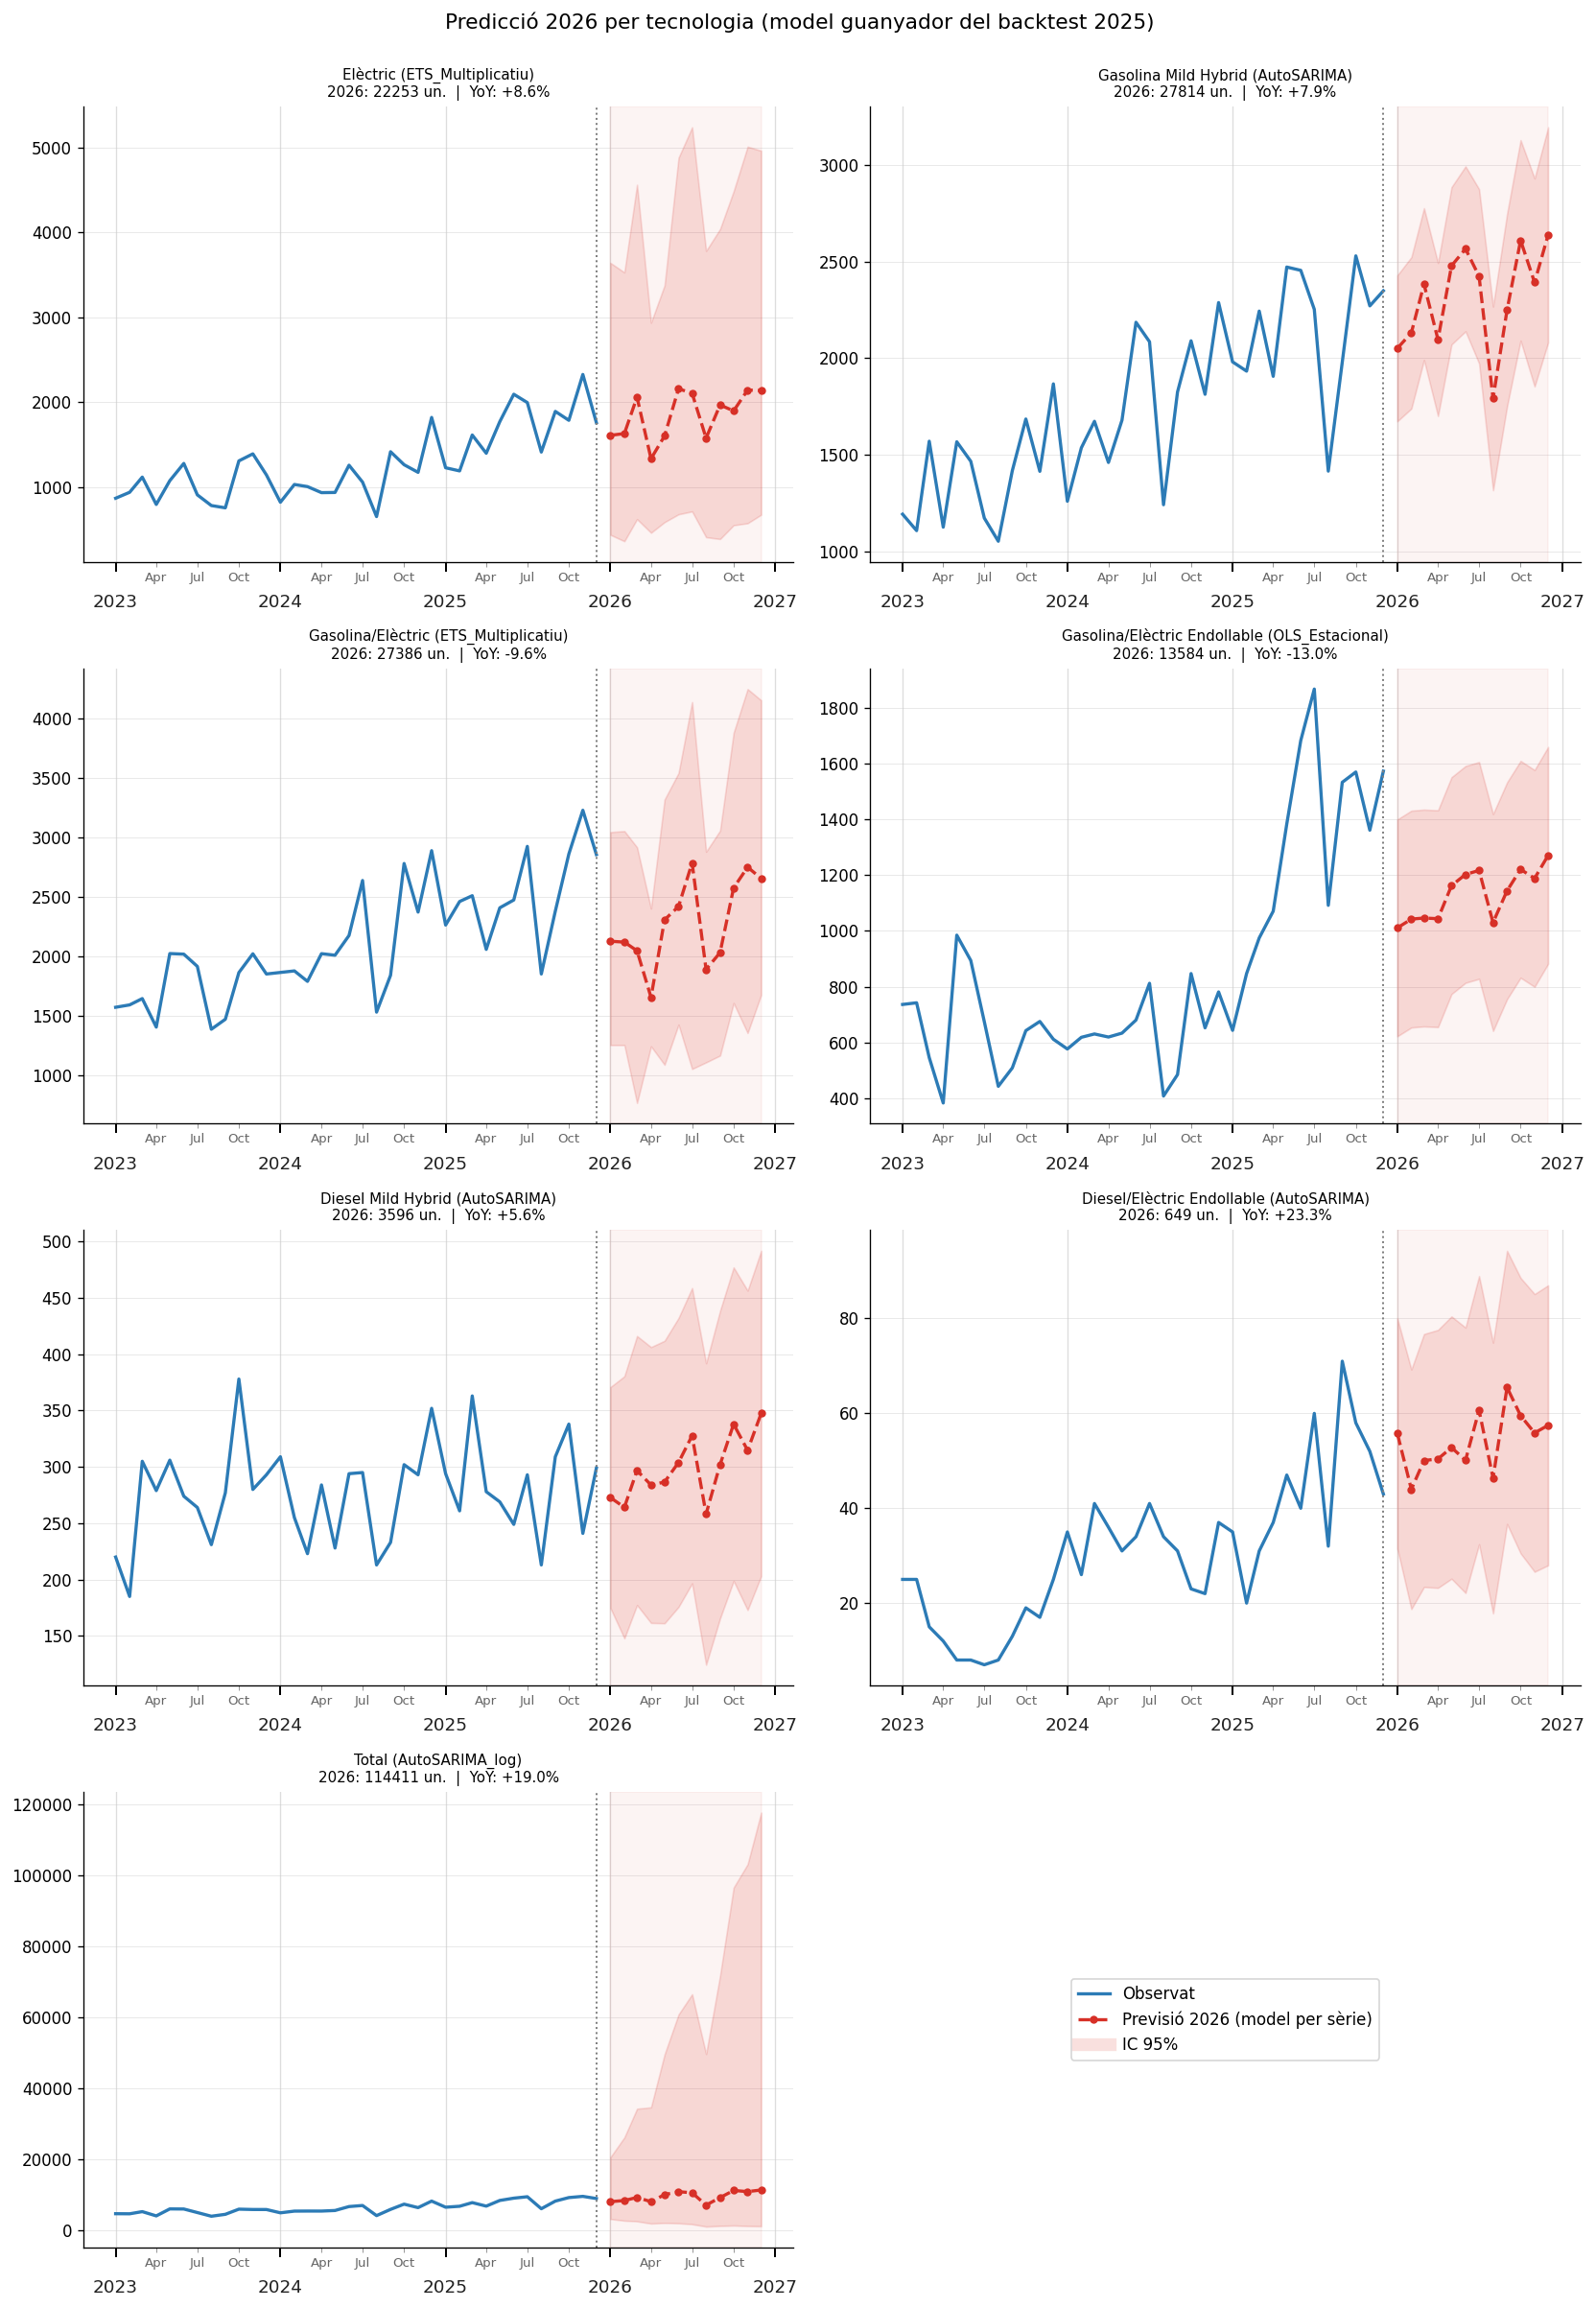

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()
TAIL = 36

for i, tech in enumerate(TECNOLOGIES):
    ax = axes_flat[i]
    model_name, _ = TECH_MODELS[tech]

    hist = pivot_full[tech].iloc[-TAIL:]
    ax.plot(hist.index, hist.values, color=COLOR_HIST, lw=2, label='Observat')
    ax.axvline(pivot_full.index[-1], color='gray', ls=':', lw=1.2)

    sub      = df_fc[df_fc['Tecnologia'] == tech].sort_values('date')
    dates_fc = pd.to_datetime(sub['date'])
    ax.plot(dates_fc, sub['predicted'], color=COLOR_FC, lw=2, ls='--',
            marker='o', ms=4, label=f'{model_name} (previsió 2026)')
    ax.fill_between(dates_fc, sub['ci_lower'], sub['ci_upper'],
                    color=COLOR_FC, alpha=0.15, label='IC 95%')
    ax.axvspan(dates_fc.iloc[0], dates_fc.iloc[-1], alpha=0.05, color=COLOR_FC)

    fc_anual  = sub['predicted'].sum()
    real_2025 = pivot_test[tech].sum()
    yoy       = (fc_anual - real_2025) / real_2025 * 100
    ax.set_title(
        f'{tech} ({model_name})\n2026: {fc_anual:.0f} un.  |  YoY: {yoy:+.1f}%',
        fontsize=9)
    format_ts_ax(ax)

for j in range(len(TECNOLOGIES), len(axes_flat)):
    axes_flat[j].axis('off')
    if j == len(axes_flat) - 1:
        from matplotlib.lines import Line2D
        legend_items = [
            Line2D([0], [0], color=COLOR_HIST, lw=2, label='Observat'),
            Line2D([0], [0], color=COLOR_FC, lw=2, ls='--', marker='o', ms=4,
                   label='Previsió 2026 (model per sèrie)'),
            Line2D([0], [0], color=COLOR_FC, lw=8, alpha=0.15, label='IC 95%'),
        ]
        axes_flat[j].legend(handles=legend_items, loc='center', fontsize=10)

plt.suptitle('Predicció 2026 per tecnologia (model guanyador del backtest 2025)',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_29_forecast_2026_per_tech.png', bbox_inches='tight')
plt.show()

## 4. Mercat total 2026

La sèrie Total agrega totes les tecnologies. El primer gràfic mostra l'historial dels últims 4 anys + la previsió 2026 amb banda de confiança. El segon compara la distribució mensual 2025 real vs 2026 prevista.

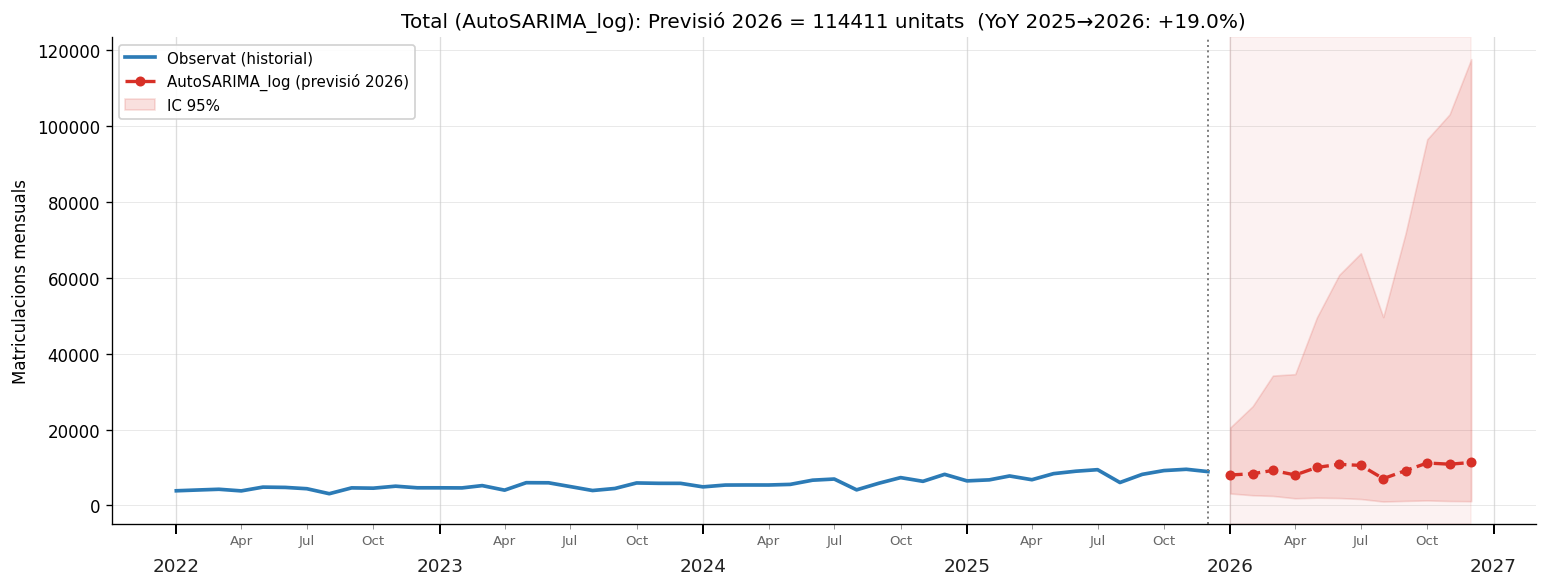

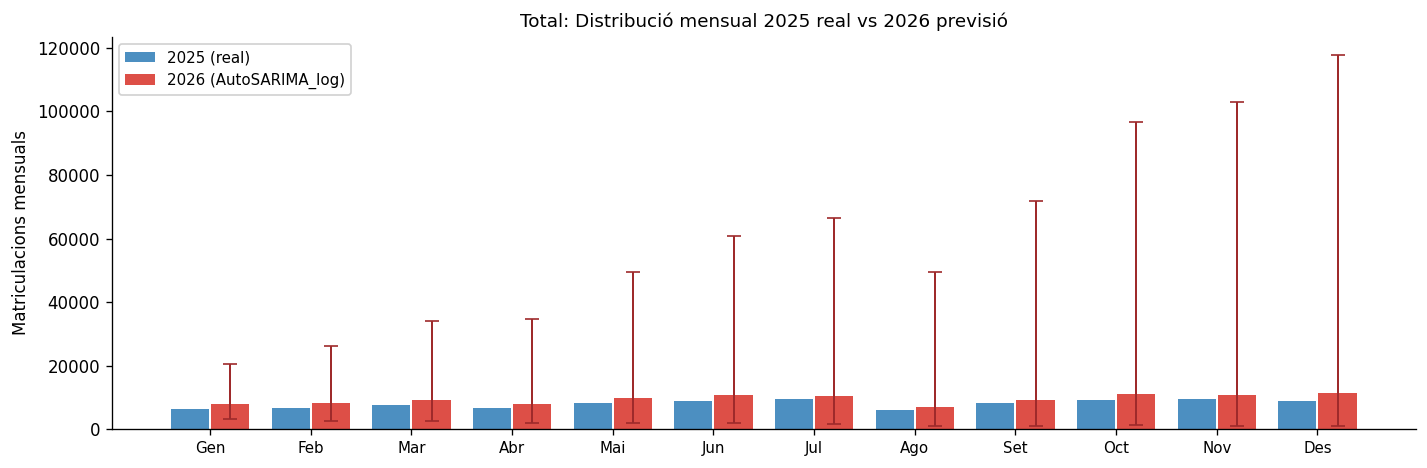

In [7]:
tech    = 'Total'
sub_tot = df_fc[df_fc['Tecnologia'] == tech].sort_values('date')
dates_tot = pd.to_datetime(sub_tot['date'])
model_name_total, _ = TECH_MODELS[tech]

# Gràfic 1: sèrie temporal amb IC
fig, ax = plt.subplots(figsize=(13, 5))
hist = pivot_full[tech].iloc[-48:]
ax.plot(hist.index, hist.values, color=COLOR_HIST, lw=2.2, label='Observat (historial)')
ax.axvline(pivot_full.index[-1], color='gray', ls=':', lw=1.2)
ax.plot(dates_tot, sub_tot['predicted'], color=COLOR_FC, lw=2,
        ls='--', marker='o', ms=5, label=f'{model_name_total} (previsió 2026)')
ax.fill_between(dates_tot, sub_tot['ci_lower'], sub_tot['ci_upper'],
                color=COLOR_FC, alpha=0.15, label='IC 95%')
ax.axvspan(dates_tot.iloc[0], dates_tot.iloc[-1], alpha=0.06, color=COLOR_FC)

fc_sum    = sub_tot['predicted'].sum()
real_2025 = pivot_test[tech].sum()
yoy       = (fc_sum - real_2025) / real_2025 * 100
ax.set_title(
    f'Total ({model_name_total}): Previsió 2026 = {fc_sum:.0f} unitats  '
    f'(YoY 2025→2026: {yoy:+.1f}%)',
    fontsize=12)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_30_forecast_2026_total.png', bbox_inches='tight')
plt.show()

# Gràfic 2: barres mensuals 2025 vs 2026
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(H)
ax.bar(x - 0.2, pivot_test[tech].values, width=0.38,
       color=COLOR_HIST, label='2025 (real)', alpha=0.85)
ax.bar(x + 0.2, sub_tot['predicted'].values, width=0.38,
       color=COLOR_FC, label=f'2026 ({model_name_total})', alpha=0.85)
ax.errorbar(
    x + 0.2, sub_tot['predicted'].values,
    yerr=[sub_tot['predicted'].values - sub_tot['ci_lower'].values,
          sub_tot['ci_upper'].values - sub_tot['predicted'].values],
    fmt='none', color='#9e2a2b', capsize=4, lw=1.2)
ax.set_xticks(x)
ax.set_xticklabels(MONTHS_CA, fontsize=9)
ax.set_ylabel('Matriculacions mensuals')
ax.set_title('Total: Distribució mensual 2025 real vs 2026 previsió', fontsize=11)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_31_forecast_2026_total_mensual.png', bbox_inches='tight')
plt.show()

## 5. Mix tecnològic 2021–2026

Com evoluciona la composició del mercat? Mostrem els volums anuals per tecnologia de 2021 a 2026 (les de 2026 són la previsió del model guanyador del backtest 2025 per a cada sèrie) en dos formats: volums absoluts (barres apilades) i quotes de mercat (%). La sèrie 'Total' s'exclou per evitar doble comptatge.

> El 2026 s'indica amb asterisc per diferenciar la previsió de les dades reals.

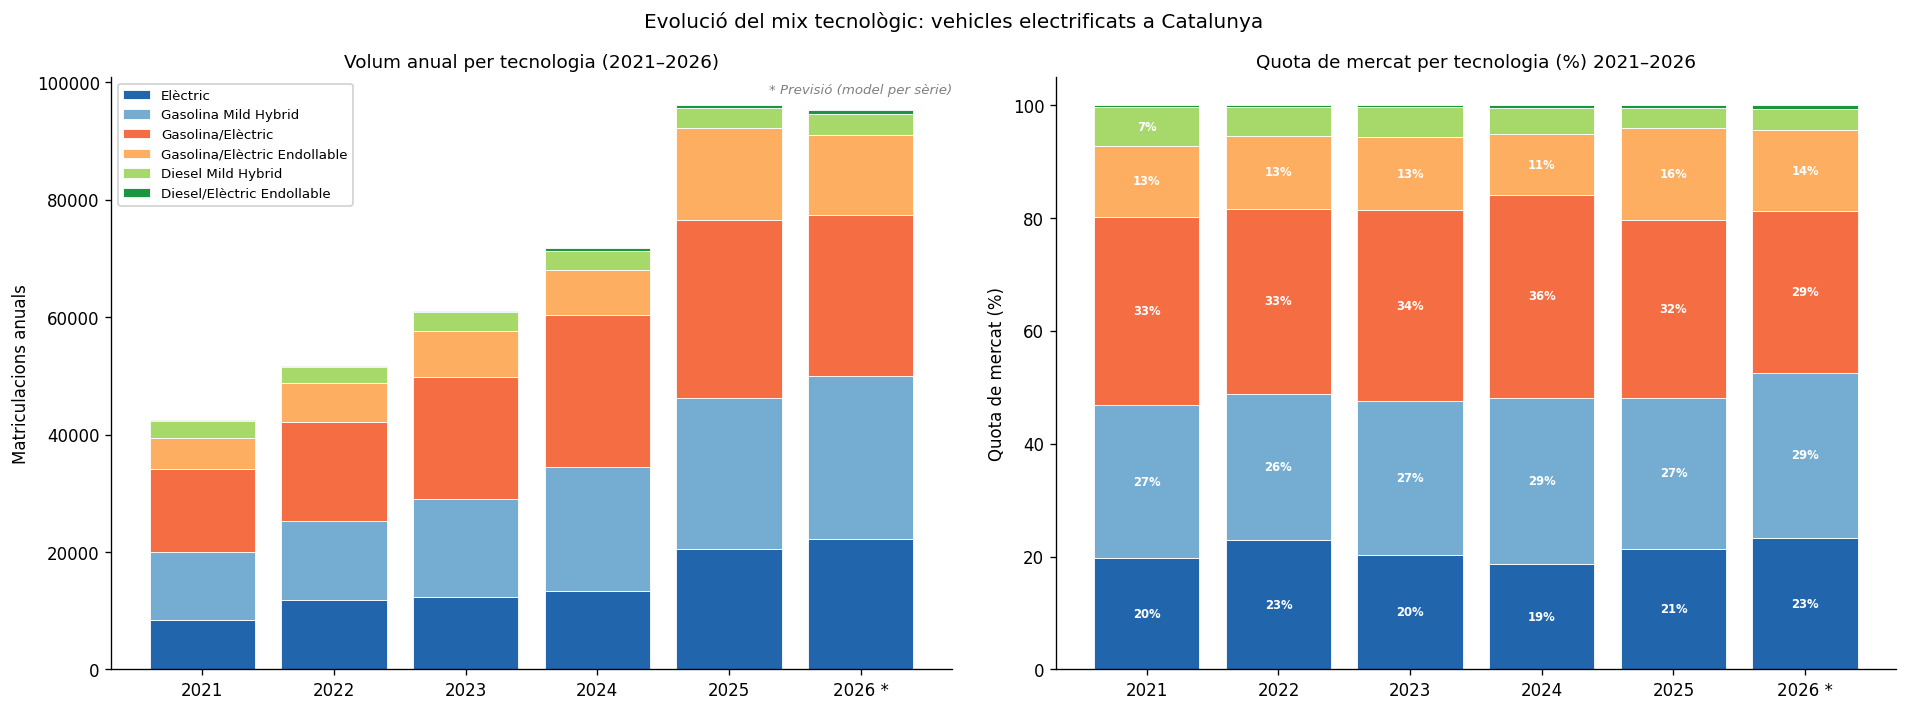

Quotes de mercat 2024 → 2025 → 2026:


,2024 (%),2025 (%),2026 (%)*
Elèctric,18.7,21.3,23.4
Gasolina Mild Hybrid,29.5,26.8,29.2
Gasolina/Elèctric,36.0,31.5,28.7
Gasolina/Elèctric Endollable,10.8,16.2,14.3
Diesel Mild Hybrid,4.6,3.5,3.8
Diesel/Elèctric Endollable,0.5,0.5,0.7


In [8]:
years_hist = [2021, 2022, 2023, 2024, 2025]
annual = {}
for year in years_hist:
    mask = pivot_full.index.year == year
    annual[year] = pivot_full.loc[mask, TECHS_NO_TOT].sum()

annual[2026] = (df_fc[df_fc['Tecnologia'].isin(TECHS_NO_TOT)]
                .groupby('Tecnologia')['predicted'].sum())

df_mix     = pd.DataFrame(annual).T[TECHS_NO_TOT]
df_mix_pct = df_mix.div(df_mix.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
years_labels = [str(y) + (' *' if y == 2026 else '') for y in df_mix.index]

# Barres apilades: volums absoluts
bottom = np.zeros(len(df_mix))
for tech in TECHS_NO_TOT:
    vals = df_mix[tech].values
    axes[0].bar(years_labels, vals, bottom=bottom,
                color=COLORS_TECH[tech], label=tech,
                edgecolor='white', linewidth=0.5)
    bottom += vals
axes[0].set_title('Volum anual per tecnologia (2021–2026)', fontsize=11)
axes[0].set_ylabel('Matriculacions anuals')
axes[0].legend(fontsize=8, loc='upper left', framealpha=0.9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].text(len(years_labels) - 1,
             df_mix.sum(axis=1).iloc[-1] * 1.03,
             '* Previsió (model per sèrie)',
             ha='center', fontsize=8, style='italic', color='gray')

# Barres apilades: quotes (%)
bottom_pct = np.zeros(len(df_mix_pct))
for tech in TECHS_NO_TOT:
    vals = df_mix_pct[tech].values
    axes[1].bar(years_labels, vals, bottom=bottom_pct,
                color=COLORS_TECH[tech], label=tech,
                edgecolor='white', linewidth=0.5)
    for j, (v, b) in enumerate(zip(vals, bottom_pct)):
        if v > 6:
            axes[1].text(j, b + v / 2, f'{v:.0f}%',
                         ha='center', va='center',
                         fontsize=7, color='white', fontweight='bold')
    bottom_pct += vals
axes[1].set_title('Quota de mercat per tecnologia (%) 2021–2026', fontsize=11)
axes[1].set_ylabel('Quota de mercat (%)')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Evolució del mix tecnològic: vehicles electrificats a Catalunya',
             fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_32_forecast_2026_mix.png', bbox_inches='tight')
plt.show()

print('Quotes de mercat 2024 → 2025 → 2026:')
display(df_mix_pct.loc[[2024, 2025, 2026]].round(1).T
        .rename(columns={2024: '2024 (%)', 2025: '2025 (%)', 2026: '2026 (%)* '}))

## 6. Creixement interanual (YoY)

Taula comparativa de volums i taxes de creixement per a cada tecnologia: 2023 real → 2024 real → 2025 real → 2026 previsió. Permet veure si el model espera acceleració, desacceleració o estabilització per a cada segment del mercat.

In [9]:
yoy_rows = []
for tech in TECNOLOGIES:
    v2023 = pivot_full[tech][pivot_full.index.year == 2023].sum()
    v2024 = pivot_full[tech][pivot_full.index.year == 2024].sum()
    v2025 = pivot_test[tech].sum()
    v2026 = df_fc[df_fc['Tecnologia'] == tech]['predicted'].sum()

    def yoy(a, b):
        """YoY % arrodonit, evita l'artefacte -0.0 de coma flotant."""
        v = round((b - a) / a * 100, 1)
        return v + 0.0  # -0.0 → 0.0 en IEEE-754

    yoy_rows.append({
        'Tecnologia':    tech,
        '2023 (real)':   int(round(v2023)),
        '2024 (real)':   int(round(v2024)),
        '2025 (real)':   int(round(v2025)),
        '2026 (prev.)':  int(round(v2026)),
        'YoY 23→24 (%)': yoy(v2023, v2024),
        'YoY 24→25 (%)': yoy(v2024, v2025),
        'YoY 25→26 (%)': yoy(v2025, v2026),
    })

df_yoy = pd.DataFrame(yoy_rows).set_index('Tecnologia').loc[TECNOLOGIES]
print('Creixements interanuals per tecnologia:')
display(df_yoy)

Creixements interanuals per tecnologia:


,2023 (real),2024 (real),2025 (real),2026 (prev.),YoY 23→24 (%),YoY 24→25 (%),YoY 25→26 (%)
Tecnologia,,,,,,,
Elèctric,12394,13401,20495,22253,8.1,52.9,8.6
Gasolina Mild Hybrid,16634,21135,25789,27814,27.1,22.0,7.9
Gasolina/Elèctric,20781,25810,30300,27386,24.2,17.4,-9.6
Gasolina/Elèctric Endollable,7836,7739,15606,13584,-1.2,101.7,-13.0
Diesel Mild Hybrid,3292,3281,3407,3596,-0.3,3.8,5.6
Diesel/Elèctric Endollable,182,391,526,649,114.8,34.5,23.3
Total,61123,71760,96175,114411,17.4,34.0,19.0


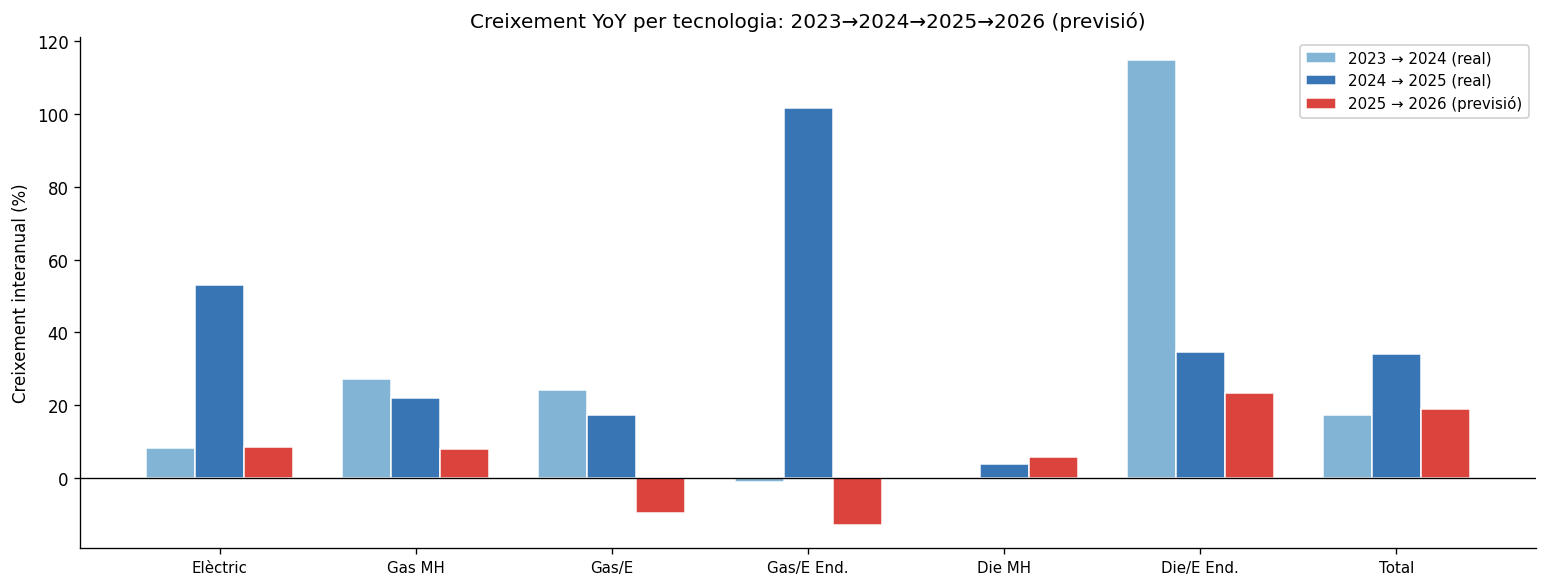

In [10]:
# Bar chart YoY: 3 columnes per tecnologia (23→24, 24→25, 25→26)
labels_short = ['Elèctric', 'Gas MH', 'Gas/E', 'Gas/E End.', 'Die MH', 'Die/E End.', 'Total']
yoy_cols   = ['YoY 23→24 (%)', 'YoY 24→25 (%)', 'YoY 25→26 (%)']
col_colors = ['#74add1', '#2166ac', '#d73027']
col_labels = ['2023 → 2024 (real)', '2024 → 2025 (real)', '2025 → 2026 (previsió)']
x = np.arange(len(TECNOLOGIES))
w = 0.25

fig, ax = plt.subplots(figsize=(13, 5))
for j, (col, color, label) in enumerate(zip(yoy_cols, col_colors, col_labels)):
    vals = df_yoy[col].values
    ax.bar(x + (j - 1) * w, vals, width=w,
           color=color, label=label, edgecolor='white', alpha=0.9)

ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels_short, fontsize=9)
ax.set_ylabel('Creixement interanual (%)')
ax.set_title('Creixement YoY per tecnologia: 2023→2024→2025→2026 (previsió)', fontsize=12)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_33_forecast_2026_yoy.png', bbox_inches='tight')
plt.show()

## 7. Conclusions

### Mercat total: +19.0% YoY → 114.411 unitats el 2026

AutoSARIMA amb log preveu un mercat total de **114.411 matrícules** el 2026, enfront de les 96.175 reals del 2025 (+19.0% YoY). La transformació log estabilitza la variança creixent de la sèrie agregada (BoxCox λ≈0.49 a l'EDA) i va capturar el cicle 2025 amb un MASE de 0.42 al backtest. La previsió manté una bona part del creixement però amb una desacceleració respecte al +34% del 2024→2025: el model identifica el 2025 com un cicle excepcional i extrapola un creixement més moderat per al 2026.

> Nota: la sèrie Total és modelada de forma independent. La suma de les sis sub-tecnologies (~95.282 unitats) no coincideix amb el Total perquè cada model fa les seves pròpies hipòtesis sobre tendència i estacionalitat. La diferència no és un error sinó una propietat de l'enfocament no-jeràrquic.

### Resultats per tecnologia

| Tecnologia | Model | 2025 (real) | 2026 (prev.) | YoY |
|---|---|---|---|---|
| **Total** | AutoSARIMA (log) | 96.175 | **114.411** | **+19.0%** |
| Gasolina Mild Hybrid | AutoSARIMA | 25.789 | 27.814 | +7.9% |
| Gasolina/Elèctric | ETS Multiplicatiu | 30.300 | 27.386 | −9.6% |
| Elèctric | ETS Multiplicatiu | 20.495 | 22.253 | +8.6% |
| Gas./Elèctric Endollable | OLS Estacional | 15.606 | 13.584 | −13.0% |
| Diesel Mild Hybrid | AutoSARIMA | 3.407 | 3.596 | +5.6% |
| Diesel/Elèctric Endollable | AutoSARIMA | 526 | 649 | +23.3% |

### Lectura per dinàmica de cada sèrie

**Sèries amb creixement moderat 2026**: Elèctric (+8.6%) i Gasolina Mild Hybrid (+7.9%). Cap dels dos models hereta la pujada del +52.9% i +22.0% del 2024→2025; ETS Multiplicatiu i AutoSARIMA atribueixen una part d'aquell salt a una component no estructural i estabilitzen la trajectòria. Diesel Mild Hybrid (+5.6%) i Diesel/Elèctric Endollable (+23.3%, sobre volum molt baix) segueixen la mateixa lògica.

**Sèries amb correcció negativa**: Gasolina/Elèctric (−9.6%) i Gasolina/Elèctric Endollable (−13.0%). Tots dos casos reflecteixen el supòsit del model que el cicle 2024→2025 va ser parcialment artificial. Especialment notable Gasolina/Elèctric Endollable: l'OLS_Estacional (que va ser el millor del backtest amb 3.97) projecta una davallada perquè la regressió lineal sobre 108 mesos veu el salt del +101.7% del 2025 com un outlier respecte d'una tendència de fons més moderada. La predicció és coherent si el règim regulatori del MOVES III es normalitza i no es repeteix l'efecte de data límit del 31-desembre-2024 ni la pròrroga amb efecte retroactiu del 2025.

### Composició del mercat 2026

Gasolina Mild Hybrid (27.814 un.) i Gasolina/Elèctric (27.386 un.) lideren el mercat individual, tots dos al voltant de les 27.500 unitats. Elèctric tercer amb 22.253, seguit de Gasolina/Elèctric Endollable (13.584). El mix de la mobilitat electrificada (BEV + PHEV) representa entre el 31% i el 36% del mercat total previst, una continuïtat aproximada respecte al 2025.

### Patró estacional 2026 (sèrie Total)

El cicle mensual previst per al Total per AutoSARIMA amb log presenta un pic concentrat al Q4 (octubre-desembre) i la vall tradicional d'agost. Aquest patró és coherent amb la dinàmica històrica del mercat català on el tancament d'objectius comercials de finals d'any concentra les matriculacions.

### Incertesa

Els intervals de confiança al 95% varien per família de models:
- **AutoSARIMA**: IC analítics que s'eixamplen amb h (la incertesa creix a mesura que ens allunyem del darrer punt observat).
- **ETS Multiplicatiu**: IC bootstrap (500 simulacions) que reflecteixen l'asimetria de la incertesa en sèries multiplicatives.
- **OLS Estacional**: IC constant basat en σ residual (assumpció d'errors i.i.d.).

A Gasolina/Elèctric (ETS Mult) i Elèctric (ETS Mult) la banda d'incertesa és especialment ampla per la variabilitat alta d'aquestes sèries durant 2024-2025.

### Limitació principal

La previsió assumeix que el context d'incentius i preus es manté el 2026. L'activació de noves convocatòries MOVES, canvis regulatoris europeus, o la consolidació d'incentius PHEV/BEV podrien alterar significativament les trajectòries projectades. Les sèries amb correcció negativa (Gasolina/Elèctric, Gasolina/Elèctric Endollable) són les més sensibles a aquesta hipòtesi de continuïtat regulatòria: si les polítiques d'incentiu es mantenen o s'amplien, el creixement real podria superar la previsió de l'extrapolació estadística. Per a una predicció més robusta de canvis estructurals caldria SARIMAX amb variables exògenes (vigència de programes, preus, xarxa de càrrega).

In [11]:
df_fc.to_csv(RESULTS_DIR / 'forecast_2026.csv', index=False)
df_info.reset_index().to_csv(RESULTS_DIR / 'forecast_2026_models.csv', index=False)
df_yoy.to_csv(RESULTS_DIR / 'forecast_2026_yoy.csv')
print('Guardats:')
print('  forecast_2026.csv         : prediccions mensuals 2026 + IC 95% per cada sèrie')
print('  forecast_2026_models.csv  : model assignat i detalls de l\'ajust per sèrie')
print('  forecast_2026_yoy.csv     : volums anuals i YoY 2023–2026')

Guardats:
  forecast_2026.csv         : prediccions mensuals 2026 + IC 95% per cada sèrie
  forecast_2026_models.csv  : model assignat i detalls de l'ajust per sèrie
  forecast_2026_yoy.csv     : volums anuals i YoY 2023–2026
